# ZOA vs all other IndiKit sites

`base_comparison.ipynb` measured every site against the base library (www.indikit.net). This notebook flips the reference point: **ZOA's library (303 indicators) is the anchor**, compared against the other 9 sites from `files/links` — the base plus adra, irw, tearfund, whh, winrock, tdh, helvetas and savethechildren. It answers:

1. which ZOA indicators other organizations also use — identically, reworded, or not at all;
2. how *standard* each ZOA indicator is (adoption count across sites) and which are ZOA-only;
3. how ZOA's wording drifts from sites that share its indicators;
4. what the others measure that ZOA doesn't — candidate gaps.

Method and plan: see `zoa_comparison_plan.md`. Uses the scraped snapshots in `data/` (no scraping); tables are written to `comparison_zoa/`.

**Caveat:** helvetas, savethechildren and tdh run custom platforms — they can only be matched via embeddings, so their "shared" counts mean *topical similarity*, not confirmed shared indicators.

In [34]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ZOA = "zoa_indikit_net"
BASE = "www_indikit_net"

frames = {p.parent.name: pd.read_json(p) for p in sorted(Path("data").glob("*/indicators.json"))}
OTHERS = sorted((d for d in frames if d != ZOA), key=lambda d: -len(frames[d]))
zoa_df = frames[ZOA]

OUT = Path("comparison_zoa")
OUT.mkdir(exist_ok=True)


def short(domain):
    return domain.replace("indicators_", "").replace("_indikit_net", "").replace("_net", "")


# chart style (dataviz reference palette, light mode)
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
C1, C2, C3 = "#2a78d6", "#1baf7a", "#eda100"  # categorical slots 1-3: blue, aqua, yellow
SEQ_BLUES = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
             "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.titlesize": 12,
    "legend.frameon": False, "font.family": "sans-serif", "font.size": 10,
})

print(f"zoa: {len(zoa_df)} indicators | compared against: {[short(d) for d in OTHERS]}")

zoa: 303 indicators | compared against: ['www', 'adra', 'irw', 'tearfund', 'savethechildren', 'whh', 'helvetas', 'tdh', 'winrock']


In [35]:
# Per-site overview. Sites on the IndiKit engine share the "How to Collect..."
# section verbatim; the others are custom platforms.
CLONE_MARKER = "section:How to Collect and Analyse the Required Data"

overview = pd.DataFrame(
    {
        "indicators": len(frames[d]),
        "sectors": frames[d]["sector"].nunique(),
        "template": "IndiKit clone" if CLONE_MARKER in frames[d].columns else "custom",
    }
    for d in [ZOA] + OTHERS
).set_axis([short(d) for d in [ZOA] + OTHERS])
overview

,indicators,sectors,template
zoa,303,30,IndiKit clone
www,518,77,IndiKit clone
adra,507,69,IndiKit clone
irw,480,52,IndiKit clone
tearfund,230,9,IndiKit clone
savethechildren,179,25,custom
whh,122,12,IndiKit clone
helvetas,87,11,custom
tdh,65,16,custom
winrock,42,11,IndiKit clone


## Matching ZOA's indicators to each site

Same three-tier ladder as `base_comparison.ipynb`, run pairwise ZOA → site: ① exact slug, ② slug text (numeric ID stripped) or exact normalized title, ③ embedding cosine ≥ 0.80 over the meaning-bearing fields. Below the cutoff = the indicator is absent from that site. Multilingual wording sections are reduced to their English text first.

In [36]:
# Normalization helpers (identical to base_comparison.ipynb)
SEMANTIC_PATTERNS = ("wording", "phrasing", "purpose", "definition", "full statement")
WORDING_PATTERNS = ("wording", "phrasing", "full statement")
LANG_LABELS = {"english", "french", "arabic", "spanish", "portuguese", "français", "francais"}


def text_slug(slug):
    return re.sub(r"^\d+-", "", str(slug))


def norm(s):
    if not isinstance(s, str):
        return ""
    s = re.sub(r"[^a-z0-9 ]", " ", s.lower())
    return re.sub(r"\s+", " ", s).strip()


def english_only(text):
    # Sites publish sections multilingually in several layouts:
    #   block:       "English\nFrench\n<en>\n<fr>"            (zoa, irw, adra)
    #   interleaved: "English:\n<en>\nFrench:\n<fr>"          (whh)
    #   tab residue: "INDICATOR PHRASING\nFrançais\n<en>\n…"  (tearfund)
    # Reduce every layout to the English text.
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if lines and lines[0].isupper() and len(lines[0]) < 40:
        lines = lines[1:]  # section-header echo, e.g. "INDICATOR PHRASING"
    is_label = [l.lower().rstrip(":") in LANG_LABELS for l in lines]
    if not any(is_label):
        return "\n".join(lines)
    i0 = is_label.index(True)
    n = 0
    while i0 + n < len(lines) and is_label[i0 + n]:
        n += 1
    head, rest = lines[:i0], lines[i0 + n:]
    if n == 1 and lines[i0].lower().rstrip(":") == "english":
        seg = []
        for k, l in enumerate(rest):
            if is_label[i0 + 1 + k]:
                break
            seg.append(l)
        return "\n".join(head + seg)
    if n == 1:
        # single non-English label: texts follow one per language, English first
        return "\n".join(head + rest[:1])
    per = len(rest) // n if rest and len(rest) % n == 0 else 1
    return "\n".join(head + rest[:per])


def field_text(row, patterns):
    parts = []
    for field, v in row.items():
        if any(p in field.lower() for p in patterns) and isinstance(v, str) and v.strip():
            parts.append(english_only(v.strip()))
    return "\n".join(parts)


for domain, df in frames.items():
    df["text_slug"] = df["slug"].map(text_slug)
    df["norm_title"] = df["title"].map(norm)
    df["wording"] = df.apply(lambda r: field_text(r, WORDING_PATTERNS), axis=1)
    df["norm_wording"] = df["wording"].map(norm)
    df["canonical"] = df.apply(lambda r: str(r["title"]) + "\n" + field_text(r, SEMANTIC_PATTERNS), axis=1)

print("derived columns ready")

derived columns ready


In [37]:
# Embeddings over canonical text — all domains
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
emb = {
    domain: model.encode(df["canonical"].tolist(), normalize_embeddings=True, show_progress_bar=False)
    for domain, df in frames.items()
}
print({short(d): e.shape for d, e in emb.items()})

{'adra': (507, 384), 'helvetas': (87, 384), 'savethechildren': (179, 384), 'irw': (480, 384), 'tdh': (65, 384), 'tearfund': (230, 384), 'whh': (122, 384), 'winrock': (42, 384), 'www': (518, 384), 'zoa': (303, 384)}


In [38]:
# The ladder, ZOA -> each site. sims matrices are kept for the reverse
# (gap) direction later.
THRESH = 0.80

lookups = {}
for d in OTHERS:
    by_slug, by_textslug, by_title = {}, {}, {}
    for j, r in frames[d].iterrows():
        by_slug.setdefault(r["slug"], j)
        by_textslug.setdefault(r["text_slug"], j)
        if r["norm_title"]:
            by_title.setdefault(r["norm_title"], j)
    lookups[d] = (by_slug, by_textslug, by_title)

sims_fwd = {d: emb[ZOA] @ emb[d].T for d in OTHERS}

rows = []
for d in OTHERS:
    by_slug, by_textslug, by_title = lookups[d]
    sims = sims_fwd[d]
    best_j = sims.argmax(axis=1)
    for i, r in zoa_df.iterrows():
        j, tier = None, None
        if r["slug"] in by_slug:
            j, tier = by_slug[r["slug"]], 1
        elif r["text_slug"] in by_textslug:
            j, tier = by_textslug[r["text_slug"]], 2
        elif r["norm_title"] and r["norm_title"] in by_title:
            j, tier = by_title[r["norm_title"]], 2
        if j is None:
            j = int(best_j[i])
            tier = 3 if sims[i, j] >= THRESH else 0
        site_row = frames[d].loc[j]
        if tier == 0:
            cls = "absent"
        elif r["norm_wording"] and r["norm_wording"] == site_row["norm_wording"]:
            cls = "identical"
        else:
            cls = "modified"
        rows.append({
            "site": d, "zoa_idx": i, "zoa_title": r["title"], "zoa_sector": r["sector"],
            "tier": tier, "site_idx": j,
            "site_title": site_row["title"] if tier else None,
            "site_sector": site_row["sector"] if tier else None,
            "similarity": round(float(sims[i, j]), 3),
            "class": cls,
        })

matches = pd.DataFrame(rows)
matches.to_csv(OUT / "zoa_matches.csv", index=False)
matches.pivot_table(index="site", columns="class", aggfunc="size", fill_value=0).reindex(OTHERS)

class,absent,identical,modified
site,,,
www_indikit_net,87,179,37
adra_indikit_net,68,218,17
irw_indikit_net,129,143,31
tearfund_indikit_net,263,4,36
indicators_savethechildren_net,300,0,3
whh_indikit_net,244,37,22
helvetas_indikit_net,302,0,1
tdh_indikit_net,303,0,0
winrock_indikit_net,302,0,1


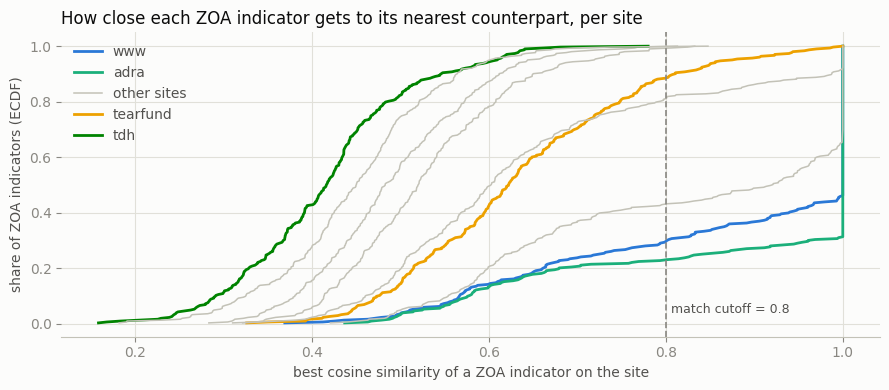

In [39]:
# Cutoff sensitivity: ECDF of each ZOA indicator's best embedding similarity,
# per site. A steep curve at the dashed line means that site's match count is
# fragile to the 0.80 cutoff choice; a flat one means it barely matters.
HIGHLIGHT = {BASE: C1, "adra_indikit_net": C2, "tearfund_indikit_net": C3, "tdh_indikit_net": "#008300"}

fig, ax = plt.subplots(figsize=(9, 4))
gray_labeled = False
for d in OTHERS:
    x = np.sort(sims_fwd[d].max(axis=1))
    yv = np.arange(1, len(x) + 1) / len(x)
    if d in HIGHLIGHT:
        ax.plot(x, yv, color=HIGHLIGHT[d], linewidth=2, label=short(d))
    else:
        ax.plot(x, yv, color=BASELINE, linewidth=1.1,
                label=None if gray_labeled else "other sites")
        gray_labeled = True
ax.axvline(THRESH, color=MUTED, linestyle="--", linewidth=1.2)
ax.text(THRESH + 0.006, 0.04, f"match cutoff = {THRESH}", color=INK2, fontsize=9)
ax.set_title("How close each ZOA indicator gets to its nearest counterpart, per site")
ax.set_xlabel("best cosine similarity of a ZOA indicator on the site")
ax.set_ylabel("share of ZOA indicators (ECDF)")
ax.legend(loc="upper left", labelcolor=INK2)
plt.tight_layout()
plt.show()

## How much of ZOA's library each site shares

Of ZOA's 303 indicators, per site: shared **identically** (word-for-word English wording), shared but **modified**, or **absent**. The custom platforms (tdh, helvetas, savethechildren) can't score "identical" — no shared wording field — so read their bars as topical overlap.

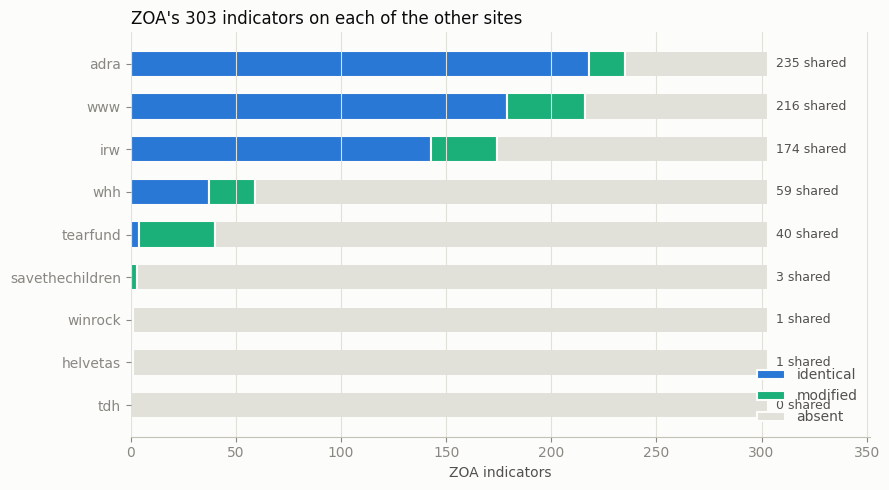

class,identical,modified,absent
site,,,
www_indikit_net,179,37,87
adra_indikit_net,218,17,68
irw_indikit_net,143,31,129
tearfund_indikit_net,4,36,263
indicators_savethechildren_net,0,3,300
whh_indikit_net,37,22,244
helvetas_indikit_net,0,1,302
tdh_indikit_net,0,0,303
winrock_indikit_net,0,1,302


In [40]:
class_counts = (
    matches.pivot_table(index="site", columns="class", aggfunc="size", fill_value=0)
    .reindex(columns=["identical", "modified", "absent"], fill_value=0)
    .reindex(OTHERS)
)

order = class_counts[["identical", "modified"]].sum(axis=1).sort_values().index
cc = class_counts.loc[order]
fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(cc))
for col, color in [("identical", C1), ("modified", C2), ("absent", GRID)]:
    ax.barh([short(d) for d in order], cc[col].to_numpy(float), left=left,
            height=0.62, color=color, edgecolor=SURFACE, linewidth=1.5, label=col)
    left += cc[col].to_numpy(float)
for y, shared in enumerate(cc[["identical", "modified"]].sum(axis=1)):
    ax.text(len(zoa_df) + 4, y, f"{shared} shared", va="center", color=INK2, fontsize=9)
ax.yaxis.grid(False)
ax.margins(x=0.16)
ax.set_title("ZOA's 303 indicators on each of the other sites")
ax.set_xlabel("ZOA indicators")
ax.legend(loc="lower right", labelcolor=INK2)
plt.tight_layout()
plt.show()

class_counts

## How standard is each ZOA indicator?

Adoption count = on how many of the 9 other sites the indicator appears. High counts mark sector-standard indicators; zero marks **ZOA-only** indicators — ZOA's own footprint.

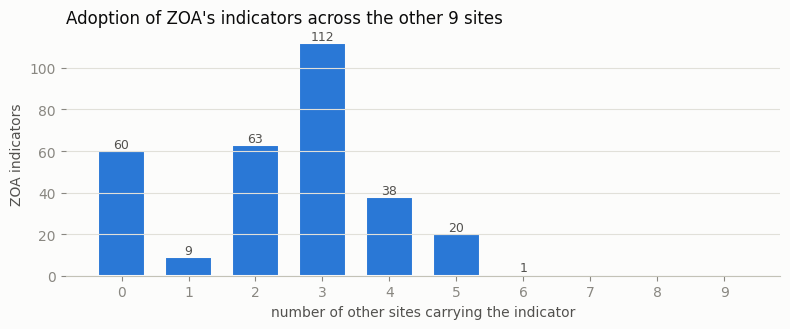

Most widely shared ZOA indicators:
                             zoa_title                         zoa_sector  adoption
                Food Consumption Score                      Food Security         6
   Use of Promoted Products / Services                 Market Development         5
   Use of Improved Sanitation Facility                         Sanitation         5
        Adoption of Promoted Practices           Project level indicators         5
Household Food Insecurity Access Scale                      Food Security         5
                     Access to Shelter                            Shelter         5
                      Increased Income              Income and Employment         5
           Acquired Knowledge / Skills Skills, Training and Employability         5
            Access to Adequate Shelter                            Shelter         5
              Access to Non-Food Items                            Shelter         5


In [41]:
coverage = (
    matches.assign(present=(matches["tier"] > 0).astype(int))
    .pivot_table(index="zoa_idx", columns="site", values="present")
    .reindex(range(len(zoa_df)), fill_value=0)
)
coverage.columns = [short(c) for c in coverage.columns]
coverage.insert(0, "zoa_title", zoa_df["title"])
coverage.insert(1, "zoa_sector", zoa_df["sector"])
coverage["adoption"] = coverage.drop(columns=["zoa_title", "zoa_sector"]).sum(axis=1).astype(int)
coverage.to_csv(OUT / "coverage_matrix.csv", index=False)

dist = coverage["adoption"].value_counts().sort_index().reindex(range(10), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(dist.index, dist.to_numpy(), color=C1, edgecolor=SURFACE, linewidth=1.5, width=0.7)
for x, v in dist.items():
    if v:
        ax.text(x, v + 1.5, str(v), ha="center", color=INK2, fontsize=9)
ax.xaxis.grid(False)
ax.set_xticks(range(10))
ax.set_title("Adoption of ZOA's indicators across the other 9 sites")
ax.set_xlabel("number of other sites carrying the indicator")
ax.set_ylabel("ZOA indicators")
plt.tight_layout()
plt.show()

print("Most widely shared ZOA indicators:")
print(coverage.sort_values("adoption", ascending=False)[["zoa_title", "zoa_sector", "adoption"]]
      .head(10).to_string(index=False))

In [42]:
# ZOA-only indicators — carried by no other site, not even the base
zoa_unique = coverage[coverage["adoption"] == 0][["zoa_title", "zoa_sector"]]
zoa_unique.to_csv(OUT / "zoa_unique.csv", index=False)
print(f"{len(zoa_unique)} ZOA-only indicators, by ZOA sector:")
print(zoa_unique["zoa_sector"].value_counts().to_string())
zoa_unique.head(15)

60 ZOA-only indicators, by ZOA sector:
zoa_sector
Organisational level indicators                       9
Sector specific results of CVA                        9
Multisectoral results related to CVA                  6
Land Rights                                           6
Group cash transfers                                  6
Process & quality management                          5
Integrated Water Resources Management                 4
Social cohesion and trust                             4
Community based conflict prevention and resolution    3
Peacebuilding - General                               3
Food Security                                         2
Project level indicators                              2
Income and Employment                                 1


,zoa_title,zoa_sector
zoa_idx,,
223,Acute malnutrition,Food Security
224,Household food production,Food Security
225,Cash Spending,Income and Employment
226,Use of EST tool,Organisational level indicators
227,Climate Resilience in Evaluations,Organisational level indicators
228,Projects with a Peace/Conflict Indicator,Organisational level indicators
229,% of Country Budget to Local Partners,Organisational level indicators
230,Peace Nexus in Evaluations,Organisational level indicators
231,Local Involvement in Project Design,Organisational level indicators


## Which parts of ZOA's framework are sector-standard?

Per ZOA sector: the share of its indicators present on each site. Dark rows = sectors built from widely used indicators; light rows = sectors that are mostly ZOA's own construction.

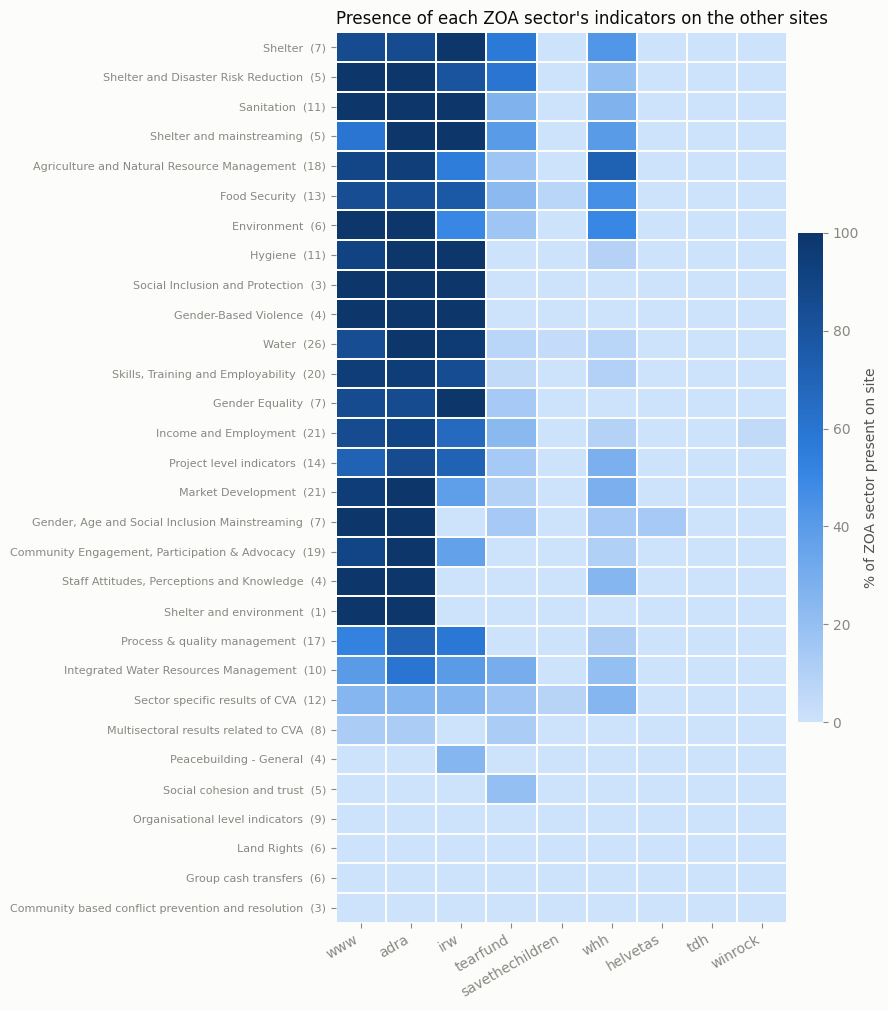

In [43]:
from matplotlib.colors import LinearSegmentedColormap

present = matches[matches["tier"] > 0]
sector_sizes = zoa_df["sector"].value_counts()
sector_cov = pd.DataFrame(index=sector_sizes.index, columns=OTHERS, dtype=float)
for d in OTHERS:
    got = present[present["site"] == d]
    got_sectors = zoa_df.loc[got["zoa_idx"].unique(), "sector"].value_counts()
    sector_cov[d] = (got_sectors.reindex(sector_sizes.index).fillna(0) / sector_sizes * 100).round(1)
sector_cov = sector_cov.loc[sector_cov.mean(axis=1).sort_values(ascending=False).index]

cmap = LinearSegmentedColormap.from_list("seq_blues", SEQ_BLUES)
fig, ax = plt.subplots(figsize=(9, 0.28 * len(sector_cov) + 1.8))
mesh = ax.pcolormesh(sector_cov.to_numpy(float), cmap=cmap, vmin=0, vmax=100,
                     edgecolors=SURFACE, linewidth=1.2)
ax.set_xticks(np.arange(len(sector_cov.columns)) + 0.5)
ax.set_xticklabels([short(d) for d in sector_cov.columns], rotation=30, ha="right")
ax.set_yticks(np.arange(len(sector_cov)) + 0.5)
ax.set_yticklabels([f"{s}  ({sector_sizes[s]})" for s in sector_cov.index], fontsize=8)
ax.invert_yaxis()
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Presence of each ZOA sector's indicators on the other sites")
cbar = fig.colorbar(mesh, ax=ax, shrink=0.55, pad=0.02)
cbar.set_label("% of ZOA sector present on site", color=INK2)
cbar.outline.set_visible(False)
plt.tight_layout()
plt.show()

### How ZOA re-files the base's indicators

For confidently matched ZOA ↔ base pairs (tiers 1-2): which base sector each kept indicator came from, and which ZOA sector it now lives in. The base's fine-grained taxonomy gets consolidated into ZOA's much smaller one — the flows show which base sectors were merged where. Only the largest flows are drawn; the remainder is reported above the chart.

top 20 flows = 103 indicators; 62 smaller flows (93 indicators) not drawn


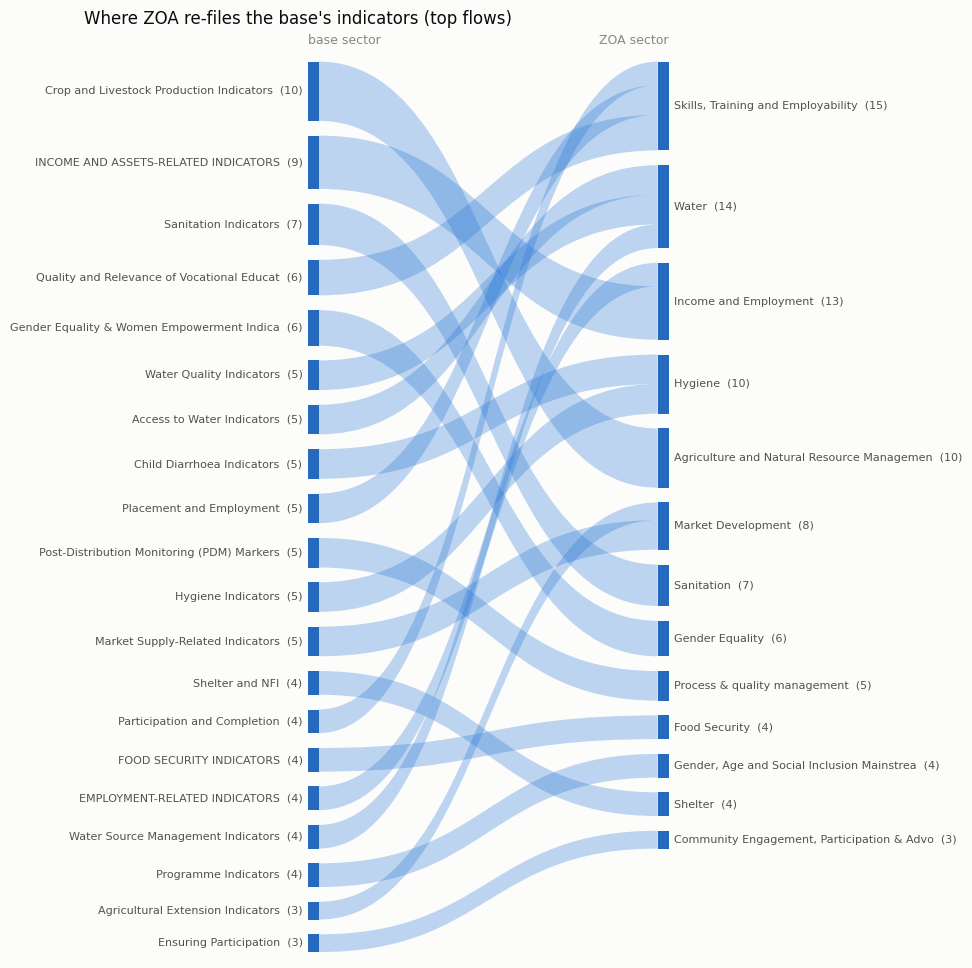

In [44]:
import matplotlib.patches as mpatches
import matplotlib.path as mpath

pairs = matches[(matches["site"] == BASE) & matches["tier"].isin([1, 2])]
flows = (pairs.groupby(["site_sector", "zoa_sector"]).size().rename("n")
         .reset_index().sort_values("n", ascending=False))
TOP = 20
shown, rest = flows.head(TOP), flows.iloc[TOP:]
print(f"top {len(shown)} flows = {shown['n'].sum()} indicators; "
      f"{len(rest)} smaller flows ({rest['n'].sum()} indicators) not drawn")

lt = shown.groupby("site_sector")["n"].sum().sort_values(ascending=False)
rt = shown.groupby("zoa_sector")["n"].sum().sort_values(ascending=False)
GAP = 2.5


def stack(totals):
    pos, y = {}, 0.0
    for name, v in totals.items():
        pos[name] = y
        y += v + GAP
    return pos


lpos, rpos = stack(lt), stack(rt)
loff = dict.fromkeys(lt.index, 0.0)
roff = dict.fromkeys(rt.index, 0.0)
H = max(lt.sum() + GAP * (len(lt) - 1), rt.sum() + GAP * (len(rt) - 1))

fig, ax = plt.subplots(figsize=(10, max(5, 0.065 * H)))
Path = mpath.Path
CODES = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO,
         Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
for f in shown.sort_values(["site_sector", "n"], ascending=[True, False]).itertuples():
    y0 = lpos[f.site_sector] + loff[f.site_sector]
    y1 = rpos[f.zoa_sector] + roff[f.zoa_sector]
    loff[f.site_sector] += f.n
    roff[f.zoa_sector] += f.n
    verts = [(0.03, y0), (0.5, y0), (0.5, y1), (0.97, y1), (0.97, y1 + f.n),
             (0.5, y1 + f.n), (0.5, y0 + f.n), (0.03, y0 + f.n), (0.03, y0)]
    ax.add_patch(mpatches.PathPatch(Path(verts, CODES), facecolor=C1, alpha=0.3, edgecolor="none"))
for name, y in lpos.items():
    ax.add_patch(mpatches.Rectangle((0.0, y), 0.03, lt[name], facecolor="#256abf", edgecolor="none"))
    ax.text(-0.015, y + lt[name] / 2, f"{name[:42]}  ({lt[name]})",
            ha="right", va="center", fontsize=8, color=INK2)
for name, y in rpos.items():
    ax.add_patch(mpatches.Rectangle((0.97, y), 0.03, rt[name], facecolor="#256abf", edgecolor="none"))
    ax.text(1.015, y + rt[name] / 2, f"{name[:42]}  ({rt[name]})",
            ha="left", va="center", fontsize=8, color=INK2)
ax.text(0.0, -GAP, "base sector", ha="left", va="bottom", fontsize=9, color=MUTED)
ax.text(1.0, -GAP, "ZOA sector", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.set_xlim(-0.62, 1.62)
ax.set_ylim(-GAP * 2, H + 1)
ax.invert_yaxis()
ax.axis("off")
ax.set_title("Where ZOA re-files the base's indicators (top flows)")
plt.tight_layout()
plt.show()

## How ZOA's wording drifts

For confidently shared but **modified** pairs (tiers 1-2, both sides with wording text): character-level similarity of the English wording — 1.0 identical, ~0.9 small edits, below ~0.5 a rewrite.

                      pairs  median
site                               
adra_indikit_net          2    0.97
irw_indikit_net          14    0.89
tearfund_indikit_net     15    0.62
whh_indikit_net           8    0.94
winrock_indikit_net       1    0.67
www_indikit_net          16    0.84


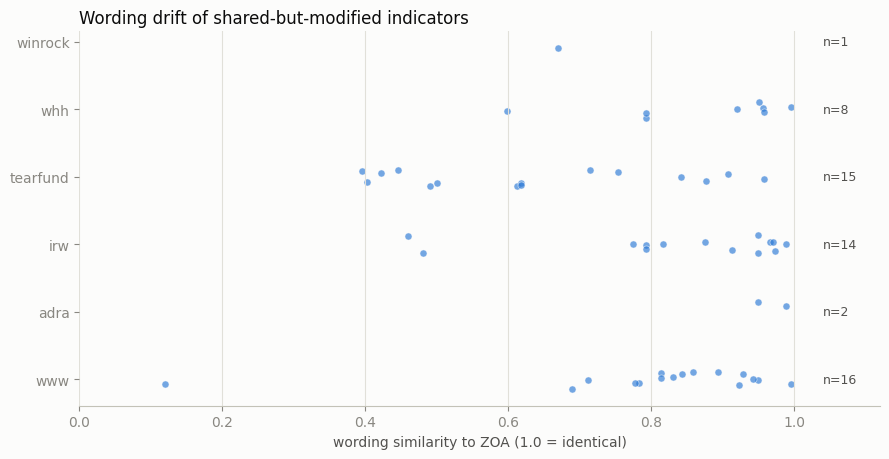


Examples — same indicator, meaningfully different wording:
Access to Adequate Shelter  vs tearfund  (wording similarity 0.402)
  ZOA : number of people having access to basic, safe and dignified shelters solutions
  SITE: Number of targeted households living in adequate shelters which meet shelter standards as defined by the cluster
Use of Promoted Products / Services  vs tearfund  (wording similarity 0.422)
  ZOA : % of households who in the past [specify number] months used the promoted [specify the product / service]
  SITE: number of target group members who used one or more of the promoted products/ services in the past 12 months
Household Food Insecurity Access Scale  vs tearfund  (wording similarity 0.446)
  ZOA : average Household Food Insecurity Access Scale Score
  SITE: % of households that are moderately or severely food insecure (according to HFIAS)


In [45]:
from difflib import SequenceMatcher

mod = matches[(matches["class"] == "modified") & matches["tier"].isin([1, 2])].copy()
mod["site_norm_wording"] = [frames[m.site].loc[m.site_idx, "norm_wording"] for m in mod.itertuples()]
mod["zoa_norm_wording"] = zoa_df.loc[mod["zoa_idx"], "norm_wording"].to_numpy()
mod = mod[(mod["zoa_norm_wording"] != "") & (mod["site_norm_wording"] != "")]
mod["wording_sim"] = [
    round(SequenceMatcher(None, a, b).ratio(), 3)
    for a, b in zip(mod["zoa_norm_wording"], mod["site_norm_wording"])
]
print(mod.groupby("site")["wording_sim"].agg(pairs="count", median="median").round(2))

# strip plot: one dot per pair — honest about small samples (a pooled
# histogram would hide that some sites contribute only a handful of pairs)
sites_present = [d for d in OTHERS if (mod["site"] == d).any()]
rng = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(9, 0.55 * len(sites_present) + 1.4))
for k, d in enumerate(sites_present):
    v = mod.loc[mod["site"] == d, "wording_sim"].to_numpy()
    ax.scatter(v, np.full(len(v), float(k)) + rng.uniform(-0.14, 0.14, len(v)),
               s=26, color=C1, alpha=0.65, edgecolors=SURFACE, linewidths=0.5)
    ax.text(1.04, k, f"n={len(v)}", va="center", color=INK2, fontsize=9)
ax.set_yticks(range(len(sites_present)))
ax.set_yticklabels([short(d) for d in sites_present])
ax.yaxis.grid(False)
ax.set_xlim(0, 1.12)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_title("Wording drift of shared-but-modified indicators")
ax.set_xlabel("wording similarity to ZOA (1.0 = identical)")
plt.tight_layout()
plt.show()

print("\nExamples — same indicator, meaningfully different wording:")
for _, m in mod[mod["wording_sim"].between(0.4, 0.75)].sort_values("wording_sim").head(3).iterrows():
    print("=" * 90)
    print(f"{m['zoa_title']}  vs {short(m['site'])}  (wording similarity {m['wording_sim']})")
    print(f"  ZOA : {zoa_df.loc[m['zoa_idx'], 'wording'][:280]}")
    print(f"  SITE: {frames[m['site']].loc[m['site_idx'], 'wording'][:280]}")

## Semantic comparison

Meaning-level view on top of the ladder, carried over from `data_analysis.ipynb`. First the **mutual best-match table**: for each ZOA indicator its closest embedding match anywhere in the other libraries, with `mutual = True` when each is the other's best match — the strongest "probably the same indicator" candidates even where slug/title matching fails (the only channel for the custom platforms). Then **free-text semantic search** across all ten libraries at once.

Caveat: embeddings measure *topical* similarity, not measurement equivalence — treat high-scoring pairs as candidates to eyeball, not confirmed matches.

In [46]:
# Mutual best matches: ZOA vs the concatenated corpus of all other libraries
corpus_others = pd.concat(
    [frames[d][["title", "sector"]].assign(site=d) for d in OTHERS],
    ignore_index=True,
)
emb_others = np.vstack([emb[d] for d in OTHERS])

sim_all = emb[ZOA] @ emb_others.T          # 303 x n_others
best_other = sim_all.argmax(axis=1)
best_zoa = sim_all.argmax(axis=0)

semantic = pd.DataFrame(
    {
        "zoa_title": zoa_df.loc[i, "title"],
        "zoa_sector": zoa_df.loc[i, "sector"],
        "match_title": corpus_others.loc[j, "title"],
        "match_site": short(corpus_others.loc[j, "site"]),
        "match_sector": corpus_others.loc[j, "sector"],
        "similarity": round(float(sim_all[i, j]), 3),
        "mutual": bool(best_zoa[j] == i),
    }
    for i, j in enumerate(best_other)
).sort_values("similarity", ascending=False).reset_index(drop=True)

semantic.to_csv(OUT / "semantic_matches.csv", index=False)
print(f"mutual top-1 pairs: {semantic['mutual'].sum()} of {len(semantic)}")
semantic.head(20)

mutual top-1 pairs: 251 of 303


,zoa_title,zoa_sector,match_title,match_site,match_sector,similarity,mutual
0,Food Consumption Score,Food Security,Food Consumption Score,adra,ACCESS TO FOOD INDICATORS,1.0,True
1,Access to Bathing Facilities,Sanitation,Access to Bathing Facilities,adra,Water Indicators,1.0,True
2,Access to Excreta Disposal Facilities,Sanitation,Access to Excreta Disposal Facilities,adra,Sanitation Indicators,1.0,True
3,Prevention of Groundwater Contamination by Faeces,Water,Prevention of Groundwater Contamination by Faeces,adra,Sanitation Indicators,1.0,True
4,Solid Waste Management,Sanitation,Solid Waste Management,adra,Solid Waste Management Indicators,1.0,True
5,Access to Hygiene Items,Hygiene,Access to Hygiene Items,www,Hygiene Indicators,1.0,True
6,Access to Adequate Shelter,Shelter,Access to Adequate Shelter,www,Shelter and NFI,1.0,True
7,Use of Cash/ Materials for Shelter (Re)Constru...,Shelter,Use of Cash/ Materials for Shelter (Re)Constru...,www,Shelter and NFI,1.0,True
8,Local Participation in Shelter Construction,Shelter and mainstreaming,Local Participation in Shelter Construction,irw,Shelter and NFI,1.0,True
9,Household Average Income,Income and Employment,Household Average Income,www,INCOME AND ASSETS-RELATED INDICATORS,1.0,True


In [47]:
# Free-text semantic search across all ten libraries
corpus_all = pd.concat(
    [frames[d][["title", "sector"]].assign(site=short(d)) for d in [ZOA] + OTHERS],
    ignore_index=True,
)
emb_all = np.vstack([emb[d] for d in [ZOA] + OTHERS])


def search(query, top_k=8):
    q = model.encode([query], normalize_embeddings=True)
    scores = (emb_all @ q.T).ravel()
    idx = scores.argsort()[::-1][:top_k]
    result = corpus_all.loc[idx, ["site", "title", "sector"]].copy()
    result.insert(0, "score", scores[idx].round(3))
    return result.reset_index(drop=True)


search("resilience of smallholder farmers to drought")

,score,site,title,sector
0,0.537,whh,#ms09 Climate Resilience - Households using th...,Environment
1,0.523,irw,Reduced Vulnerability to Climate Change,Global Results Framework
2,0.500,tearfund,Increase in climate-resilient employment oppor...,Environment and Climate Change
3,0.496,tearfund,Adoption of Resilience Strengthening Measures,"Disaster Preparedness, Anticipation and Resili..."
4,0.482,helvetas,WFC 1.10 People more resilient to the adverse ...,People
5,0.476,tearfund,Water resources - climate resilience monitoring,"Water, sanitation and hygiene (WASH)"
6,0.469,helvetas,WFC 1.7 Smallholders implementing climate-resi...,People
7,0.468,savethechildren,Uptake of diversified / climate-resilient live...,Diversified/climate-resilient livelihood options


In [48]:
search("safe drinking water access in rural communities")

,score,site,title,sector
0,0.616,adra,Treatment of Drinking Water,Water Indicators
1,0.616,zoa,Treatment of Drinking Water,Water
2,0.616,www,Treatment of Drinking Water,Water Quality Indicators
3,0.616,irw,Treatment of Drinking Water,Water Indicators
4,0.588,whh,Household water treatment and safe storage (HWTS),WASH
5,0.586,savethechildren,Safely managed drinking water,"Access to at least basic drinking water, basic..."
6,0.567,tearfund,Institutional settings - basic drinking water,"Water, sanitation and hygiene (WASH)"
7,0.559,zoa,Water Access Safety,Water


## What the others measure that ZOA doesn't

Reverse direction: each site's indicators with no ZOA counterpart (same ladder, site → ZOA). The per-site counts show how much of their library lies outside ZOA's scope and in which of *their* sectors; the base's uncovered indicators are the canonical candidate list for additions.

In [49]:
# reverse ladder: site indicator -> any ZOA counterpart?
zoa_by_slug, zoa_by_textslug, zoa_by_title = {}, {}, {}
for j, r in zoa_df.iterrows():
    zoa_by_slug.setdefault(r["slug"], j)
    zoa_by_textslug.setdefault(r["text_slug"], j)
    if r["norm_title"]:
        zoa_by_title.setdefault(r["norm_title"], j)

gap_rows = []
for d in OTHERS:
    df = frames[d]
    best = sims_fwd[d].max(axis=0)  # per site indicator: best cosine vs any ZOA indicator
    covered = (
        df["slug"].isin(zoa_by_slug)
        | df["text_slug"].isin(zoa_by_textslug)
        | df["norm_title"].isin(zoa_by_title)
        | (best >= THRESH)
    )
    gaps = df[~covered]
    top = gaps["sector"].value_counts().head(3)
    tops = ", ".join(f"{s} ({n})" for s, n in top.items())
    gap_rows.append({"site": short(d), "indicators": len(df), "not_in_zoa": len(gaps),
                     "not_in_zoa_pct": round(100 * len(gaps) / len(df), 1)})
    print(f"{short(d):16s} {len(gaps):4d}/{len(df):4d} not in ZOA | top sectors: {tops}")
    if d == BASE:
        base_gaps = gaps

gaps_overview = pd.DataFrame(gap_rows).set_index("site")

base_gaps[["title", "sector"]].to_csv(OUT / "gaps_base.csv", index=False)
print(f"\nBase indicators without a ZOA counterpart, by base sector (top 15 of {len(base_gaps)}):")
print(base_gaps["sector"].value_counts().head(15).to_string())

www               301/ 518 not in ZOA | top sectors: Treatment of Acute Malnutrition Indicators (13), Antenatal Indicators (13), Social and Behaviour Change (12)
adra              265/ 507 not in ZOA | top sectors: Antenatal Indicators (14), Good Governance (13), Social and Behaviour Change (12)
irw               296/ 480 not in ZOA | top sectors: Global Results Framework (81), Social Protection and Inclusion (16), Antenatal Indicators (15)
tearfund          188/ 230 not in ZOA | top sectors: Water, sanitation and hygiene (WASH) (57), Gender-based violence (GBV) and psychosocial support (PSS) (33), Peacebuilding (24)
savethechildren   176/ 179 not in ZOA | top sectors: Other Strategy Indicators (50), Output Indicators (49), Institutions with basic drinking water, limited sanitation or hygiene services (12)
whh                69/ 122 not in ZOA | top sectors: Environment (12), Education and Skills Development (11), Civil Society (9)
helvetas           86/  87 not in ZOA | top sectors: P

## Deep dives: Tearfund, WHH and Save the Children

Three sites at increasing distance from ZOA get the same in-depth battery:

- **Tearfund** — same IndiKit engine, yet almost none of ZOA's library appears on it. Different themes, or the same themes measured with differently constructed indicators?
- **WHH** — same engine, mid-range overlap, thematically close to ZOA (food security / WASH). Where exactly does the overlap stop?
- **Save the Children** — entirely custom platform: no slug/title channel, so everything is embedding-based *topical* similarity; their wording comes from the `Definition` field and "identical" is impossible by construction.

The battery per site: ① full overlap inventory, ② near-misses (0.60–0.80 — same topic, different construction), ③ topical sector coverage in both directions, ④ a t-SNE topical map (base gray, ZOA blue, site yellow; qualitative only — the projection distorts distances), ⑤ measurement-style comparison (unit type + subject, regex over the full libraries), ⑥ the site's own territory (best similarity to ZOA < 0.6).

In [50]:
# Shared deep-dive helpers, parameterized by site
from sklearn.manifold import TSNE

TF, WHH, SCI = "tearfund_indikit_net", "whh_indikit_net", "indicators_savethechildren_net"


def display_wording(df):
    # savethechildren has no wording/phrasing field — fall back to its Definition
    w = df["wording"]
    if (w == "").all():
        w = df.apply(lambda r: field_text(r, ("definition",)), axis=1)
    return w


def dd_inventory(site):
    pairs = matches[(matches["site"] == site) & (matches["tier"] > 0)]
    print(f"ZOA indicators with a {short(site)} counterpart: {len(pairs)} of {len(zoa_df)}")
    return (pairs[["zoa_title", "zoa_sector", "site_title", "site_sector", "tier", "similarity", "class"]]
            .sort_values("similarity", ascending=False).reset_index(drop=True))


def dd_near_misses(site, lo=0.60):
    df, sims = frames[site], sims_fwd[site]
    best_j, best = sims.argmax(axis=1), sims.max(axis=1)
    matched_idx = set(matches[(matches["site"] == site) & (matches["tier"] > 0)]["zoa_idx"])
    site_w = display_wording(df)
    near = pd.DataFrame({
        "zoa_title": zoa_df["title"], "zoa_sector": zoa_df["sector"],
        "site_title": df.loc[best_j, "title"].to_numpy(),
        "site_sector": df.loc[best_j, "sector"].to_numpy(),
        "similarity": best.round(3),
        "zoa_wording": zoa_df["wording"].str.slice(0, 150),
        "site_wording": site_w.loc[best_j].str.slice(0, 150).to_numpy(),
    })
    near = near[(near["similarity"] >= lo) & (near["similarity"] < THRESH)
                & (~near.index.isin(matched_idx))].sort_values("similarity", ascending=False)
    near.to_csv(OUT / f"{short(site)}_near_misses.csv", index=False)
    print(f"{len(near)} near-misses ({lo} <= similarity < {THRESH})")
    return near


def dd_sector_coverage(site):
    # topical_pct = share of the sector's indicators with best similarity >= 0.6
    # matched_pct = share above the 0.80 match cutoff
    def one_direction(df, best_sims):
        return (pd.DataFrame({"sector": df["sector"], "best": best_sims})
                .groupby("sector")["best"]
                .agg(n="count",
                     topical_pct=lambda s: round(100 * (s >= 0.6).mean(), 1),
                     matched_pct=lambda s: round(100 * (s >= THRESH).mean(), 1))
                .sort_values("topical_pct", ascending=False))

    sims = sims_fwd[site]
    print(f"ZOA sectors — how far {short(site)} covers them topically:")
    print(one_direction(zoa_df, sims.max(axis=1)).to_string())
    print(f"\n{short(site)} sectors — how far ZOA covers them topically:")
    print(one_direction(frames[site], sims.max(axis=0)).to_string())


def dd_tsne(site):
    df = frames[site]
    pts = np.vstack([emb[BASE], emb[ZOA], emb[site]])
    xy = TSNE(n_components=2, random_state=0, init="pca", perplexity=30).fit_transform(pts)
    n_base, n_zoa = len(frames[BASE]), len(zoa_df)
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.scatter(xy[:n_base, 0], xy[:n_base, 1], s=12, color=BASELINE, alpha=0.55,
               edgecolors="none", label=f"base ({n_base})")
    ax.scatter(xy[n_base:n_base + n_zoa, 0], xy[n_base:n_base + n_zoa, 1], s=20, color=C1,
               alpha=0.8, edgecolors="none", label=f"zoa ({n_zoa})")
    ax.scatter(xy[n_base + n_zoa:, 0], xy[n_base + n_zoa:, 1], s=20, color=C3,
               alpha=0.8, edgecolors="none", label=f"{short(site)} ({len(df)})")
    # label the biggest sectors of ZOA and the site at their centroids
    for df_, sl in [(zoa_df, slice(n_base, n_base + n_zoa)), (df, slice(n_base + n_zoa, None))]:
        sub = xy[sl]
        for sector in df_["sector"].value_counts().head(3).index:
            m = (df_["sector"] == sector).to_numpy()
            ax.annotate(str(sector)[:34], (sub[m, 0].mean(), sub[m, 1].mean()),
                        color=INK, fontsize=8, ha="center", fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"Topical map of base, ZOA and {short(site)} indicators (t-SNE)")
    ax.legend(loc="upper right", labelcolor=INK2)
    plt.tight_layout()
    plt.show()


def unit_type(w):
    w = re.sub(r"^the ", "", str(w).strip().lower())
    if w.startswith("%") or w.startswith("percentage") or w.startswith("percent"):
        return "% of ..."
    if w.startswith(("number", "no.", "#", "total number")):
        return "number of ..."
    if w.startswith(("average", "mean", "median")) or "score" in w[:40]:
        return "score / average"
    return "other"


SUBJECTS = ["household", "individual", "child", "farmer", "wom", "communit", "people", "beneficiar"]


def subject(w):
    w = str(w).lower()
    for s in SUBJECTS:
        if s in w[:120]:
            return s
    return "none of these"


def dd_style(site):
    site_w = display_wording(frames[site])
    style = pd.DataFrame({
        "library": ["zoa"] * len(zoa_df) + [short(site)] * len(site_w),
        "unit": [unit_type(w) for w in list(zoa_df["wording"]) + list(site_w)],
        "subject": [subject(w) for w in list(zoa_df["wording"]) + list(site_w)],
    })
    print("Unit type (% of each library):")
    print((pd.crosstab(style["library"], style["unit"], normalize="index") * 100).round(1).to_string())
    print("\nFirst subject mentioned in the wording (% of each library):")
    print((pd.crosstab(style["library"], style["subject"], normalize="index") * 100).round(1).to_string())


def dd_only(site, lo=0.6):
    df = frames[site]
    best = sims_fwd[site].max(axis=0)
    only = df.loc[best < lo, ["title", "sector"]]
    only.to_csv(OUT / f"{short(site)}_only.csv", index=False)
    print(f"{len(only)} of {len(df)} {short(site)} indicators have no topical ZOA counterpart "
          f"(best < {lo}), by sector:")
    print(only["sector"].value_counts().to_string())
    return only


print("deep-dive helpers ready")

deep-dive helpers ready


### Tearfund vs ZOA

In [51]:
dd_inventory(TF)

ZOA indicators with a tearfund counterpart: 40 of 303


,zoa_title,zoa_sector,site_title,site_sector,tier,similarity,class
0,Area of Degraded Land Under Sustainable Manage...,Integrated Water Resources Management,Area of Degraded Land Under Sustainable Manage...,Environment and Climate Change,2,1.000,identical
1,Women’s Economic Decision-Making,Income and Employment,Women’s Economic Decision-Making,Livelihoods & Agriculture,2,0.989,identical
2,Protection of Services / Infrastructure Agains...,Shelter and Disaster Risk Reduction,Protection of Services Against Hazards,"Disaster Preparedness, Anticipation and Resili...",3,0.986,modified
3,Extent of Soil Erosion,Integrated Water Resources Management,Area Affected by Erosion,Environment and Climate Change,3,0.970,modified
4,Food Consumption Score,Food Security,Food Consumption Score,Livelihoods & Agriculture,2,0.958,modified
5,FSL: Coping Strategy Index,Sector specific results of CVA,Coping Strategy Index,Livelihoods & Agriculture,3,0.957,identical
6,Living Below the Poverty Line,Income and Employment,Living Below the Poverty Line,Livelihoods & Agriculture,2,0.944,modified
7,Use of Cash/ Materials for Shelter (Re)Constru...,Shelter,Use of Cash / In-Kind Shelter Assistance,Disaster Response,3,0.942,modified
8,Natural Resource Management,Integrated Water Resources Management,Effective Natural Resources Management System,"Disaster Preparedness, Anticipation and Resili...",3,0.939,modified
9,Trust,Social cohesion and trust,V6: Trust,Gender-based violence (GBV) and psychosocial s...,3,0.923,identical


In [52]:
dd_near_misses(TF).head(12)

135 near-misses (0.6 <= similarity < 0.8)


,zoa_title,zoa_sector,site_title,site_sector,similarity,zoa_wording,site_wording
63,Local Participation in Shelter Construction,Shelter and mainstreaming,Cash / In-Kind Shelter Assistance,Disaster Response,0.799,number of local people involved in voluntary o...,Number of households that were provided with c...
187,Area of Land Under Improved Management,Agriculture and Natural Resource Management,Area of Degraded Land Under Sustainable Manage...,Environment and Climate Change,0.790,hectares of land managed using environmentally...,number of hectares of the target land that is ...
123,Food Insecurity Experience Scale (FIES),Food Security,Household Food Insecurity Access Scale,Livelihoods & Agriculture,0.788,Food Insecurity Experience Scale,% of households that are moderately or severel...
216,Adoption of Environmental Protection Practices,Environment,Use of Environmentally-Sensitive Practices,Environment and Climate Change,0.786,% of [specify the target group] who practice t...,% of target group members using promoted envir...
172,Marketing Practices Leading to Higher Sales,Market Development,Benefits of Improved Marketing,Livelihoods & Agriculture,0.786,% of [specify: farmers / shop keepers / servic...,% of households reporting an increase in their...
72,Access to Public Infrastructure / Services,Shelter,Protection of Services Against Hazards,"Disaster Preparedness, Anticipation and Resili...",0.784,number of individuals with safe and equal acce...,number of essential service providers and infr...
28,Handwashing Facilities With Soap and Water,Water,"Handwashing facility, soap, water, percent of HHH","Water, sanitation and hygiene (WASH)",0.778,% of households with handwashing facilities wi...,Percent of households with soap and water at a...
117,"Drinking Water Quality (fecal contamination, h...",Water,Water: HHs with zero fecal coliforms,"Water, sanitation and hygiene (WASH)",0.776,% of households whose drinking water contains ...,Percent of households whose drinking water sup...
238,Protection Mainstreaming,Process & quality management,Assistance Delivery,Disaster Response,0.772,"Percent of recipients (disaggregated by sex, a...",% of beneficiaries reporting that humanitarian...
175,Awareness of Community Feedback and Response M...,Process & quality management,Awareness of Feedback and Response Mechanism,Disaster Response,0.771,% of [specify the target group] who know how t...,% of target household representatives aware of...


In [53]:
dd_sector_coverage(TF)

ZOA sectors — how far tearfund covers them topically:
                                                     n  topical_pct  matched_pct
sector                                                                          
Environment                                          6        100.0         16.7
Shelter and environment                              1        100.0          0.0
Shelter and mainstreaming                            5        100.0         40.0
Shelter and Disaster Risk Reduction                  5        100.0         60.0
Sanitation                                          11         90.9         27.3
Hygiene                                             11         90.9          0.0
Integrated Water Resources Management               10         90.0         30.0
Shelter                                              7         85.7         42.9
Project level indicators                            14         78.6          7.1
Water                                               26 

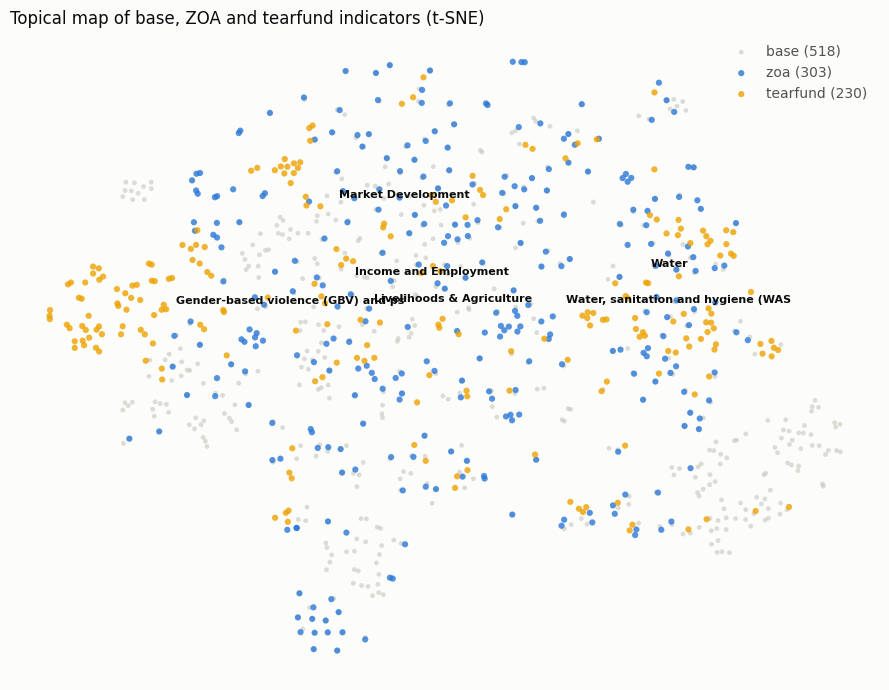

In [54]:
dd_tsne(TF)

In [55]:
dd_style(TF)

Unit type (% of each library):
unit      % of ...  number of ...  other  score / average
library                                                  
tearfund      43.9           49.1    6.5              0.4
zoa           52.8           26.4   10.2             10.6

First subject mentioned in the wording (% of each library):
subject   beneficiar  child  communit  farmer  household  individual  none of these  people  wom
library                                                                                         
tearfund         0.9    0.4       8.7     0.0       19.1         5.7           47.4    14.3  3.5
zoa              1.7    3.0       5.6     4.0       18.5         0.7           57.8     4.6  4.3


In [56]:
dd_only(TF).head(12)

102 of 230 tearfund indicators have no topical ZOA counterpart (best < 0.6), by sector:
sector
Gender-based violence (GBV) and psychosocial support (PSS)    25
Peacebuilding                                                 22
Water, sanitation and hygiene (WASH)                          20
Mobilising the church for integral mission                    19
Environment and Climate Change                                 5
Advocacy                                                       5
Livelihoods & Agriculture                                      4
Disaster Response                                              1
Disaster Preparedness, Anticipation and Resilience             1


,title,sector
13,Knowledge of Solutions to Breastfeeding Diffic...,Livelihoods & Agriculture
16,Minimum Acceptable Diet,Livelihoods & Agriculture
17,Exclusive Breastfeeding,Livelihoods & Agriculture
47,Green Jobs Creation,Environment and Climate Change
59,Early Warning Systems,"Disaster Preparedness, Anticipation and Resili..."
68,Perceived Usefulness of Protection Services,Gender-based violence (GBV) and psychosocial s...
70,Community-Managed Protection Mechanisms,Gender-based violence (GBV) and psychosocial s...
71,Perceived Safety,Gender-based violence (GBV) and psychosocial s...
72,Negative Coping Strategies,Gender-based violence (GBV) and psychosocial s...
73,Actual Number of Direct Beneficiaries,Gender-based violence (GBV) and psychosocial s...


### WHH vs ZOA

In [57]:
dd_inventory(WHH)

ZOA indicators with a whh counterpart: 59 of 303


,zoa_title,zoa_sector,site_title,site_sector,tier,similarity,class
0,Use of Promoted Products / Services,Market Development,Use of Promoted Products / Services,Agriculture and NRM,2,1.000,identical
1,Soil Quality,Agriculture and Natural Resource Management,Soil Quality,Agriculture and NRM,2,1.000,identical
2,Storage-Related Post-Harvest Losses,Agriculture and Natural Resource Management,Storage-Related Post-Harvest Losses,Agriculture and NRM,2,1.000,identical
3,Reported Agricultural Output,Agriculture and Natural Resource Management,Reported Agricultural Output,Agriculture and NRM,2,1.000,identical
4,Reported Crop Yield Per Unit,Agriculture and Natural Resource Management,Reported Crop Yield Per Unit,Agriculture and NRM,2,1.000,identical
5,Agricultural Productivity,Agriculture and Natural Resource Management,Agricultural Productivity,Agriculture and NRM,2,1.000,identical
6,Cropping Area,Agriculture and Natural Resource Management,Cropping Area,Agriculture and NRM,2,1.000,identical
7,Farm Diversity Score,Agriculture and Natural Resource Management,Farm Diversity Score,Agriculture and NRM,2,1.000,identical
8,Crop Production,Agriculture and Natural Resource Management,Crop Production,Agriculture and NRM,2,1.000,identical
9,Animal Raising,Agriculture and Natural Resource Management,Animal Raising,Agriculture and NRM,2,1.000,identical


In [58]:
dd_near_misses(WHH).head(12)

94 near-misses (0.6 <= similarity < 0.8)


,zoa_title,zoa_sector,site_title,site_sector,similarity,zoa_wording,site_wording
60,Access to Hygiene Items,Hygiene,Access to Hygiene Items (NFI-Kit),WASH,0.797,number of people having access to basic hygien...,The indicator assesses the number of the targe...
82,Successfully Trained Teachers/ Trainers,"Skills, Training and Employability",Successfully Trained Facilitators/ Trainers,Education and Skills Development,0.797,number or % of VET teachers/ trainers who succ...,number or % of TVET teachers/ trainers who suc...
130,Favourable Attitude,"Community Engagement, Participation & Advocacy",Favourable Attitude Towards a Promoted Eco-Fri...,Environment,0.794,% of [specify the target group] with a favoura...,% of [specify the target group] with a favoura...
238,Protection Mainstreaming,Process & quality management,Mainstreaming Protection in Assistance Delivery,Protection Mainstreaming,0.789,"Percent of recipients (disaggregated by sex, a...",% of beneficiaries reporting that humanitarian...
157,Number of Jobs Created,Income and Employment,Number of full-time (equivalent) jobs created,Market Development,0.787,number of full-time equivalent (FTE) jobs created,Net number of direct and indirect full-time (e...
140,Life Skills Learning,"Skills, Training and Employability",Life Skills,Education and Skills Development,0.780,number or % of participants who have gained th...,Increased life skills at the conclusion of tra...
72,Access to Public Infrastructure / Services,Shelter,Protection of Services / Infrastructure Agains...,Environment,0.778,number of individuals with safe and equal acce...,number of essential service providers and infr...
94,Safe and Dignified Shelters,Shelter,Access to Adequate Shelter,Shelter and NFI,0.772,% of target population living in safe and dign...,"number of people having access to basic, safe ..."
129,Saving and Loan Groups – Total Value of Provid...,Income and Employment,Value of Loans Accessed,Market Development,0.770,total value of loans provided by the target sa...,total value of promoted loans accessed by [spe...
110,Testing of Promoted Practices,Integrated Water Resources Management,Adoption of Promoted Practices,Agriculture and NRM,0.763,number or % of trained farmers who in the past...,number or % of farmers who for the past [speci...


In [59]:
dd_sector_coverage(WHH)

ZOA sectors — how far whh covers them topically:
                                                     n  topical_pct  matched_pct
sector                                                                          
Environment                                          6        100.0         50.0
Staff Attitudes, Perceptions and Knowledge           4        100.0         25.0
Agriculture and Natural Resource Management         18         88.9         72.2
Food Security                                       13         84.6         46.2
Sanitation                                          11         81.8         27.3
Market Development                                  21         81.0         28.6
Gender Equality                                      7         71.4          0.0
Shelter                                              7         71.4         42.9
Project level indicators                            14         64.3         21.4
Hygiene                                             11      

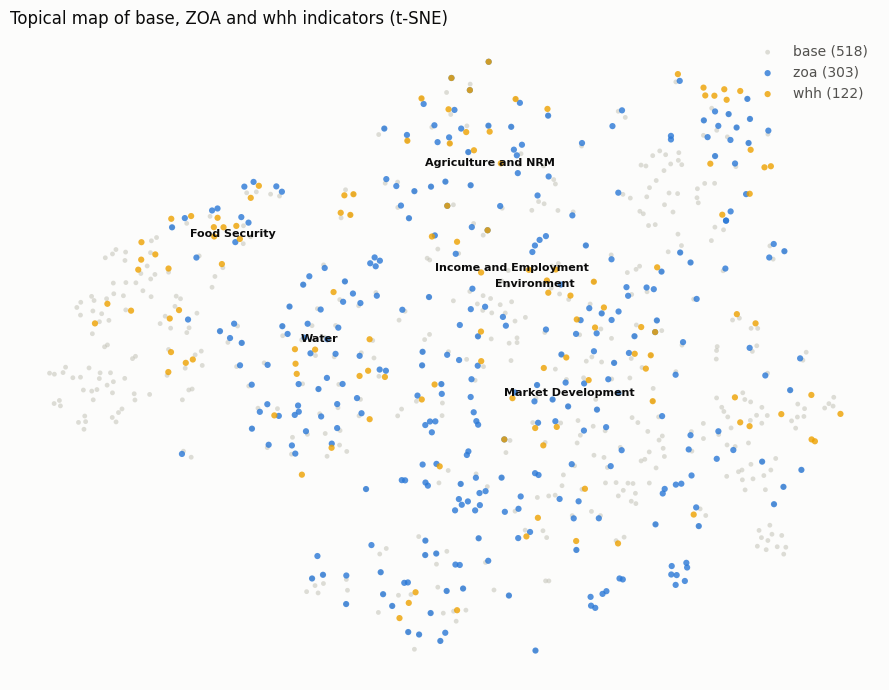

In [60]:
dd_tsne(WHH)

In [61]:
dd_style(WHH)

Unit type (% of each library):
unit     % of ...  number of ...  other  score / average
library                                                 
whh          39.3           42.6    8.2              9.8
zoa          52.8           26.4   10.2             10.6

First subject mentioned in the wording (% of each library):
subject  beneficiar  child  communit  farmer  household  individual  none of these  people  wom
library                                                                                        
whh             0.8    9.8       3.3     7.4       21.3         1.6           46.7     5.7  3.3
zoa             1.7    3.0       5.6     4.0       18.5         0.7           57.8     4.6  4.3


In [62]:
dd_only(WHH).head(12)

29 of 122 whh indicators have no topical ZOA counterpart (best < 0.6), by sector:
sector
Nutrition                           7
Civil Society                       5
Environment                         4
Education and Skills Development    4
Market Development                  3
WASH                                2
Food Security                       2
Protection Mainstreaming            1
Gender                              1


,title,sector
7,Early Initiation of Breastfeeding,Nutrition
8,Exclusive Breastfeeding Under Six Months,Nutrition
10,"Prevalence of Acute Malnutrition (MUAC, oedema)",Nutrition
11,Recovery Rate (of children in treatment),Nutrition
12,Death Rate,Nutrition
13,Defaulter Rate,Nutrition
14,Non-Recovery Rate,Nutrition
46,Multi Actor Partnerships (MAP),Civil Society
51,CSOs' Capacity to Influence Policy Making,Civil Society
83,Exposure to Household Air Pollution,Environment


### Save the Children vs ZOA

Reminder: custom platform — all matches here are embedding-based topical similarity, wording comes from their `Definition` field, and "identical" cannot occur.

In [63]:
dd_inventory(SCI)

ZOA indicators with a savethechildren counterpart: 3 of 303


,zoa_title,zoa_sector,site_title,site_sector,tier,similarity,class
0,FSL: Reduced Coping Strategy Index,Sector specific results of CVA,Households with a rCSI score over 19 (%),Households with acceptable access to food,3,0.833,modified
1,Food Consumption Score,Food Security,Acceptable Food consumption Score (FCS),Households with acceptable access to food,3,0.824,modified
2,Handwashing Facilities With Soap and Water,Water,Handwashing with soap and water,"Access to at least basic drinking water, basic...",3,0.805,modified


In [64]:
dd_near_misses(SCI).head(12)

63 near-misses (0.6 <= similarity < 0.8)


,zoa_title,zoa_sector,site_title,site_sector,similarity,zoa_wording,site_wording
2,FSL: Food Consumption Score,Sector specific results of CVA,Acceptable Food consumption Score (FCS),Households with acceptable access to food,0.782,% of the target population with acceptable Foo...,Definition\nThe Food Consumption Score (FCS) i...
7,Appropriate Treatment of Diarrhoea - ORS,Hygiene,Children with diarrhoea receiving Oral Rehydra...,Treatment of focus childhood illnesses (pneumo...,0.781,% of children aged 8 - 23/ 59 months with diar...,Definition\nThis indicator measures the percen...
32,Use of Improved Sanitation Facility,Sanitation,Households Basic Sanitation,"Access to at least basic drinking water, basic...",0.781,% of households using basic sanitation services,Definition\nThis indicator measures the propor...
165,Attitudes Towards Gender Equality,Gender Equality,Gender equitable norms,Other Strategy Indicators,0.753,% of [specify the target group] with attitudes...,Definition\nThis indicator looks at support fo...
183,Diversified Income,Income and Employment,Uptake of diversified / climate-resilient live...,Diversified/climate-resilient livelihood options,0.748,number or % of households that gained addition...,Definition\nThis indicator measures the percen...
237,Basic Needs (Alternative),Multisectoral results related to CVA,Households meeting basic needs (%),Other Strategy Indicators,0.747,Percentage of households who report being able...,Definition\nThis indicator measures the percen...
223,Acute malnutrition,Food Security,Malnutrition recovery,Other Strategy Indicators,0.747,"By Programme closure date, the prevalence and ...",Definition\nThis indicator tracks how many chi...
141,Number of Households Supported to Meet Basic N...,Process & quality management,Households meeting basic needs (%),Other Strategy Indicators,0.736,number of households that received [specify th...,Definition\nThis indicator measures the percen...
11,Access to Drinking Water,Water,Households Basic Water,"Access to at least basic drinking water, basic...",0.731,number or % of the target households using bas...,Definition\nThis indicator measures the propor...
30,Hygiene Education at Schools,Hygiene,School Basic Hygiene,"Institutions with basic drinking water, limite...",0.730,number or % of students who received hygiene e...,Definition\nThis indicator measures the propor...


In [65]:
dd_sector_coverage(SCI)

ZOA sectors — how far savethechildren covers them topically:
                                                     n  topical_pct  matched_pct
sector                                                                          
Sector specific results of CVA                      12         75.0          8.3
Hygiene                                             11         72.7          0.0
Sanitation                                          11         72.7          0.0
Food Security                                       13         69.2          7.7
Shelter                                              7         57.1          0.0
Multisectoral results related to CVA                 8         37.5          0.0
Gender, Age and Social Inclusion Mainstreaming       7         28.6          0.0
Water                                               26         26.9          3.8
Staff Attitudes, Perceptions and Knowledge           4         25.0          0.0
Social cohesion and trust                       

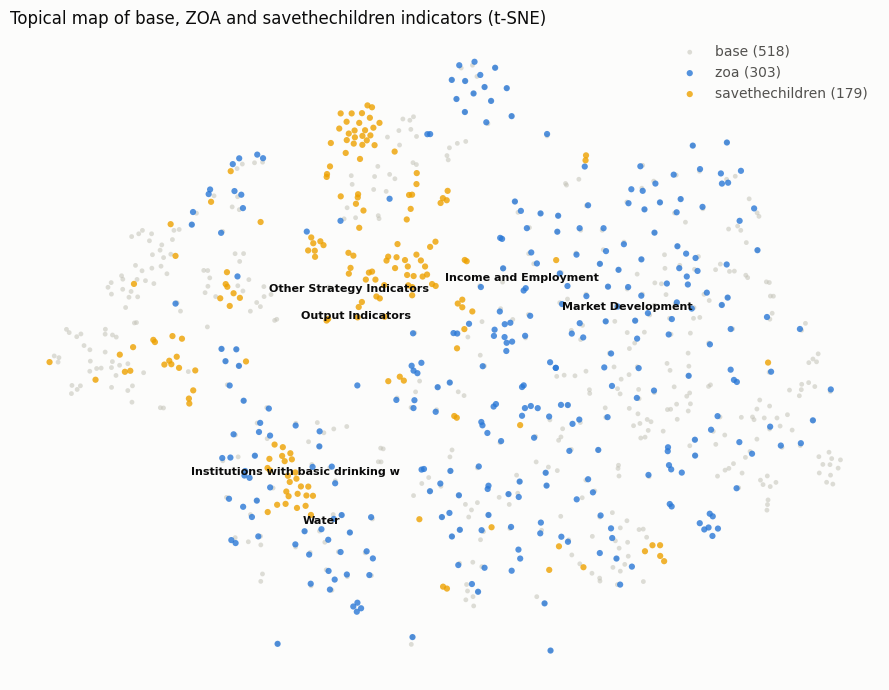

In [66]:
dd_tsne(SCI)

In [67]:
dd_style(SCI)

Unit type (% of each library):
unit             % of ...  number of ...  other  score / average
library                                                         
savethechildren       0.0           14.0   85.5              0.6
zoa                  52.8           26.4   10.2             10.6

First subject mentioned in the wording (% of each library):
subject          beneficiar  child  communit  farmer  household  individual  none of these  people  wom
library                                                                                                
savethechildren         0.6   36.9       2.8     0.0       10.6         8.9           35.2     1.7  3.4
zoa                     1.7    3.0       5.6     4.0       18.5         0.7           57.8     4.6  4.3


In [68]:
dd_only(SCI).head(12)

127 of 179 savethechildren indicators have no topical ZOA counterpart (best < 0.6), by sector:
sector
Output Indicators                                                                                                                                                                                39
Other Strategy Indicators                                                                                                                                                                        37
Children Achieving Foundational level in Literacy                                                                                                                                                 9
Children Achieving Foundational level in Numeracy                                                                                                                                                 8
Teachers/facilitators teaching at a proficient competency level                                                   

,title,sector
1,Gender equality coordination,"Supported CSOs, Child-Focused Organizations, C..."
3,# of sector-specific action plans at national ...,Output Indicators
4,Abilities of children to exercise civil rights...,Supported Children and Civil Society Actors Re...
5,Coordination by adult-led civil society organi...,"Supported CSOs, Child-Focused Organizations, C..."
7,# of people reached through anticipatory actions,Output Indicators
8,Youth trained or employed,Other Strategy Indicators
9,Adolescent and youth in employment or decent work,"Adolescent and youth in employment, education ..."
10,Adolescent and youth in further education and ...,"Adolescent and youth in employment, education ..."
11,Adolescent and youth life skills improvement,Other Strategy Indicators
12,Financial diversification of local actors,Other Strategy Indicators


### Deep-dive conclusions

*(filled in from the actual numbers after the run — one short verdict per site: where its overlap with ZOA stops, and why)*

## Summary

*(interpretation filled in below the final table)*

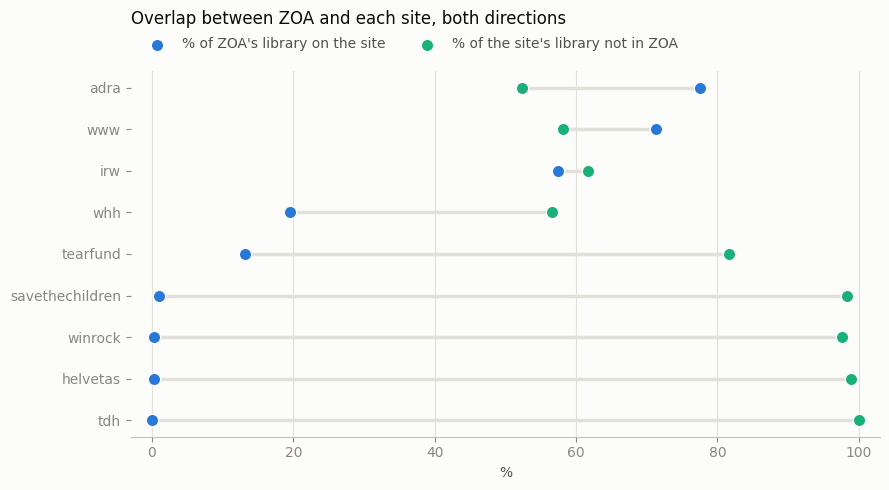

,identical,modified,absent,shared,zoa_covered_pct,indicators,not_in_zoa,not_in_zoa_pct
www,179,37,87,216,71.3,518,301,58.1
adra,218,17,68,235,77.6,507,265,52.3
irw,143,31,129,174,57.4,480,296,61.7
tearfund,4,36,263,40,13.2,230,188,81.7
savethechildren,0,3,300,3,1.0,179,176,98.3
whh,37,22,244,59,19.5,122,69,56.6
helvetas,0,1,302,1,0.3,87,86,98.9
tdh,0,0,303,0,0.0,65,65,100.0
winrock,0,1,302,1,0.3,42,41,97.6


In [69]:
summary = class_counts.copy()
summary["shared"] = summary["identical"] + summary["modified"]
summary["zoa_covered_pct"] = (100 * summary["shared"] / len(zoa_df)).round(1)
summary = summary.join(gaps_overview[["indicators", "not_in_zoa", "not_in_zoa_pct"]]
                       .set_axis(OTHERS))
summary.index = [short(d) for d in summary.index]
summary.to_csv(OUT / "summary.csv")

# dumbbell: two dots per site — the line length is the asymmetry between
# "how much of ZOA they carry" and "how much of theirs lies outside ZOA"
s = summary.sort_values("zoa_covered_pct")
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(9, 5))
for yi, (a, b) in enumerate(zip(s["zoa_covered_pct"], s["not_in_zoa_pct"])):
    ax.plot([a, b], [yi, yi], color=GRID, linewidth=2.5, zorder=1)
ax.scatter(s["zoa_covered_pct"], y, s=80, color=C1, zorder=2,
           edgecolors=SURFACE, linewidths=1, label="% of ZOA's library on the site")
ax.scatter(s["not_in_zoa_pct"], y, s=80, color=C2, zorder=2,
           edgecolors=SURFACE, linewidths=1, label="% of the site's library not in ZOA")
ax.set_yticks(y)
ax.set_yticklabels(s.index)
ax.yaxis.grid(False)
ax.set_xlim(-3, 103)
ax.set_title("Overlap between ZOA and each site, both directions", pad=34)
ax.set_xlabel("%")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncols=2, labelcolor=INK2)
plt.tight_layout()
plt.show()

summary